# Human Activity Recognition (HAR) — Activity Recognition System

## Project objective
Build and evaluate machine-learning models that recognize six human activities from smartphone inertial sensor data.

**Dataset:** UCI Human Activity Recognition Using Smartphones (UCI HAR)

The dataset contains recordings from 30 volunteers performing six activities. Each sample is a 2.56-second window containing 128 readings sampled at 50 Hz.

### Activities
1. Walking
2. Walking Upstairs
3. Walking Downstairs
4. Sitting
5. Standing
6. Laying

### Workflow
1. Load and inspect the dataset.
2. Explore activity labels and sensor signals.
3. Build a small set of statistical features from body acceleration.
4. Train a Random Forest using the custom features.
5. Compare it with the dataset's 561 engineered features.
6. Inspect feature importance and perform a gravity-feature ablation experiment.
7. Prepare raw nine-channel signals and a subject-independent validation split for a future 1D CNN.

> The CNN data preparation is included, but a CNN has **not yet been trained or evaluated** in this notebook.

## 1. Setup and load the dataset

The following cell downloads and extracts the official UCI HAR archive. If the dataset is already present in the runtime, it skips the download.

In [ ]:
import os
import zipfile
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

DATA_DIR = Path("/content/ars_data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

# The ZIP archive name inside the official URL
ZIP_PATH = DATA_DIR / "uci_har.zip"
DATASET_DIR = DATA_DIR / "UCI HAR Dataset"

url = (
    "https://archive.ics.uci.edu/static/public/240/"
    "human+activity+recognition+using+smartphones.zip"
)

if not DATASET_DIR.exists():
    print("Downloading UCI HAR dataset...")
    urllib.request.urlretrieve(url, ZIP_PATH)

    print("Extracting dataset...")
    with zipfile.ZipFile(ZIP_PATH, "r") as archive:
        bad_file = archive.testzip()
        if bad_file is not None:
            raise RuntimeError(f"Corrupt archive member: {bad_file}")
        archive.extractall(DATA_DIR)

    # Note: Sometimes double-zipped structure exists. Let's check and extract any nested zip if needed.
    nested_zip = DATA_DIR / "UCI HAR Dataset.zip"
    if nested_zip.exists():
        print("Extracting nested UCI HAR Dataset.zip...")
        with zipfile.ZipFile(nested_zip, "r") as archive:
            archive.extractall(DATA_DIR)

print("Dataset directory:", DATASET_DIR)
print("Dataset exists:", DATASET_DIR.exists())
if DATASET_DIR.exists():
    print("Contents of dataset directory:", os.listdir(DATASET_DIR))

Extracting dataset...
Extracting nested UCI HAR Dataset.zip...
Dataset directory: /content/ars_data/UCI HAR Dataset
Dataset exists: True
Contents of dataset directory: ['activity_labels.txt', 'features.txt', 'test', 'train', 'README.txt', 'features_info.txt', '.DS_Store']


## 2. Load labels, subjects, and the provided 561-feature matrices

The official training and test sets are separated by participant. We verify that no participant appears in both sets. This matters because evaluating on participants already seen during training could give an overly optimistic estimate of generalization.

In [ ]:
# Activity names
activity_labels = pd.read_csv(
    DATASET_DIR / "activity_labels.txt",
    sep=r"\s+",
    header=None,
    names=["activity_id", "activity_name"]
)
label_map = dict(zip(activity_labels["activity_id"], activity_labels["activity_name"]))

# Labels and participant IDs
y_train = np.loadtxt(DATASET_DIR / "train" / "y_train.txt", dtype=int)
y_test = np.loadtxt(DATASET_DIR / "test" / "y_test.txt", dtype=int)

subjects_train = np.loadtxt(
    DATASET_DIR / "train" / "subject_train.txt", dtype=int
)
subjects_test = np.loadtxt(
    DATASET_DIR / "test" / "subject_test.txt", dtype=int
)

# Dataset-provided engineered features
X_561 = pd.read_csv(
    DATASET_DIR / "train" / "X_train.txt",
    sep=r"\s+",
    header=None
)
X_test_561 = pd.read_csv(
    DATASET_DIR / "test" / "X_test.txt",
    sep=r"\s+",
    header=None
)

print("Training feature matrix:", X_561.shape)
print("Test feature matrix:", X_test_561.shape)
print("Training labels:", y_train.shape)
print("Test labels:", y_test.shape)
print("Training participants:", len(np.unique(subjects_train)))
print("Test participants:", len(np.unique(subjects_test)))
print("Participant overlap:", set(subjects_train) & set(subjects_test))
print("\nActivity labels:")
print(activity_labels.to_string(index=False))

Training feature matrix: (7352, 561)
Test feature matrix: (2947, 561)
Training labels: (7352,)
Test labels: (2947,)
Training participants: 21
Test participants: 9
Participant overlap: set()

Activity labels:
 activity_id      activity_name
           1            WALKING
           2   WALKING_UPSTAIRS
           3 WALKING_DOWNSTAIRS
           4            SITTING
           5           STANDING
           6             LAYING


## 3. Exploratory data analysis

### Activity distribution
Check how many windows belong to each activity in the training and test sets.

,Training,Testing
LAYING,1407,537
SITTING,1286,491
STANDING,1374,532
WALKING,1226,496
WALKING_DOWNSTAIRS,986,420
WALKING_UPSTAIRS,1073,471


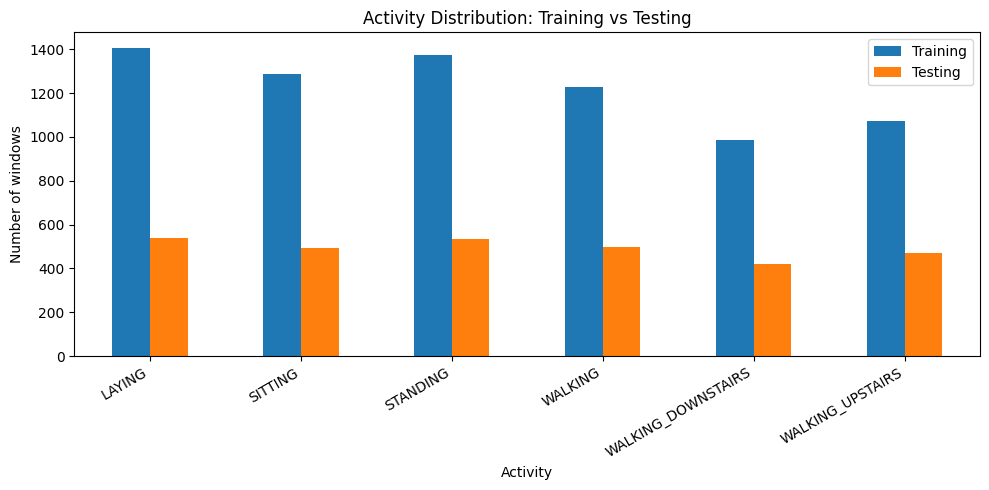

In [ ]:
train_counts = pd.Series(y_train).map(label_map).value_counts().sort_index()
test_counts = pd.Series(y_test).map(label_map).value_counts().sort_index()

distribution = pd.DataFrame({
    "Training": train_counts,
    "Testing": test_counts
})

display(distribution)

distribution.plot(kind="bar", figsize=(10, 5))
plt.title("Activity Distribution: Training vs Testing")
plt.xlabel("Activity")
plt.ylabel("Number of windows")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### Inspect sensor signals

Each window contains 128 time steps. The following plots compare body-acceleration and gyroscope signals for one example window from each activity.

These are illustrative examples, not averages across all participants.

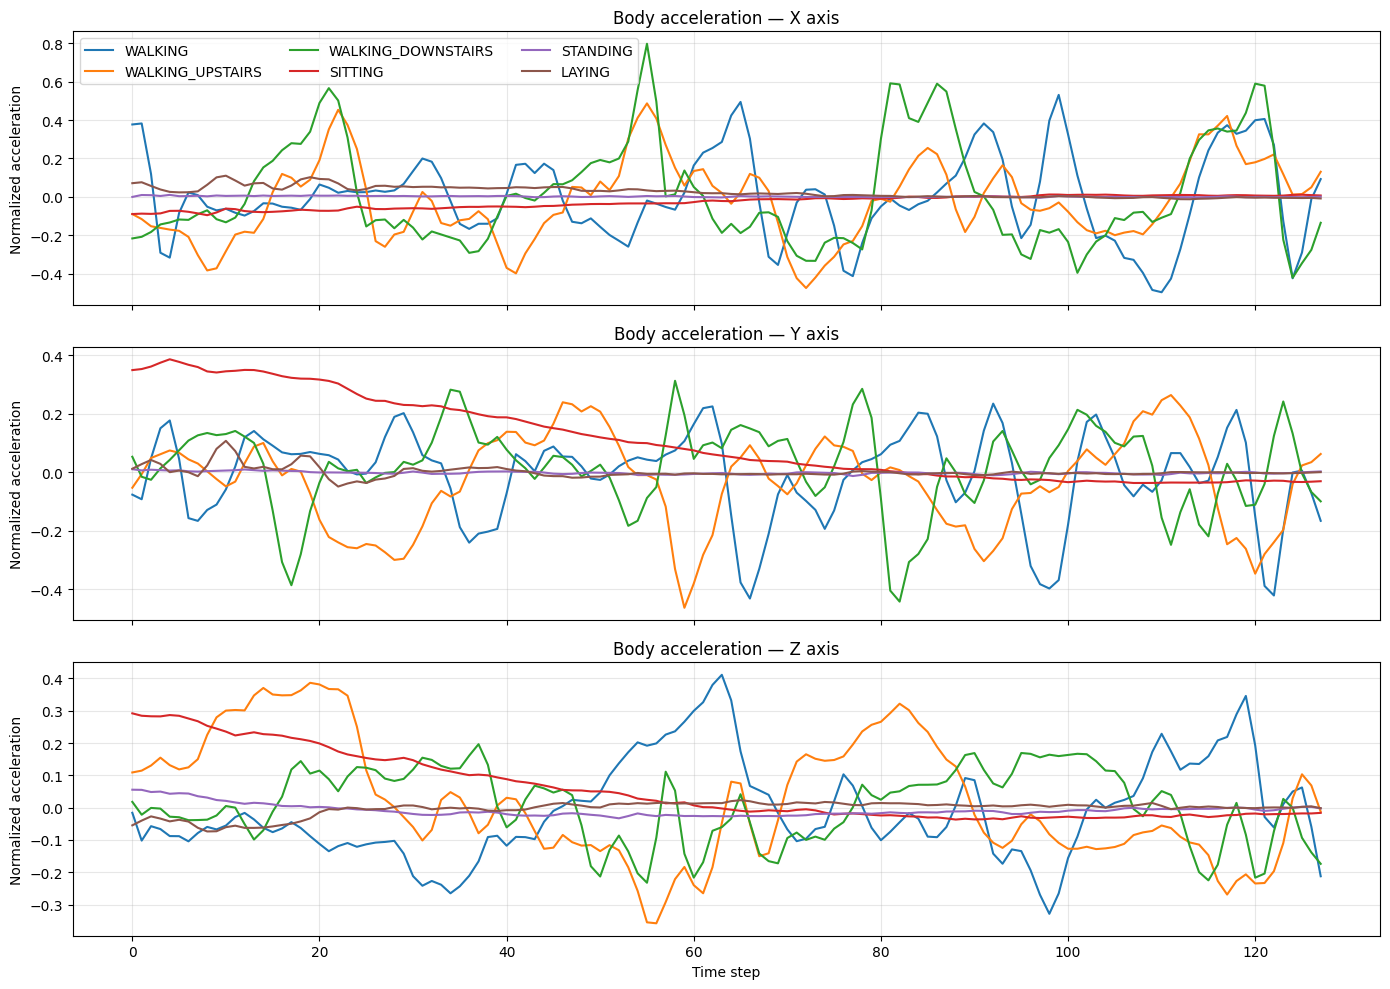

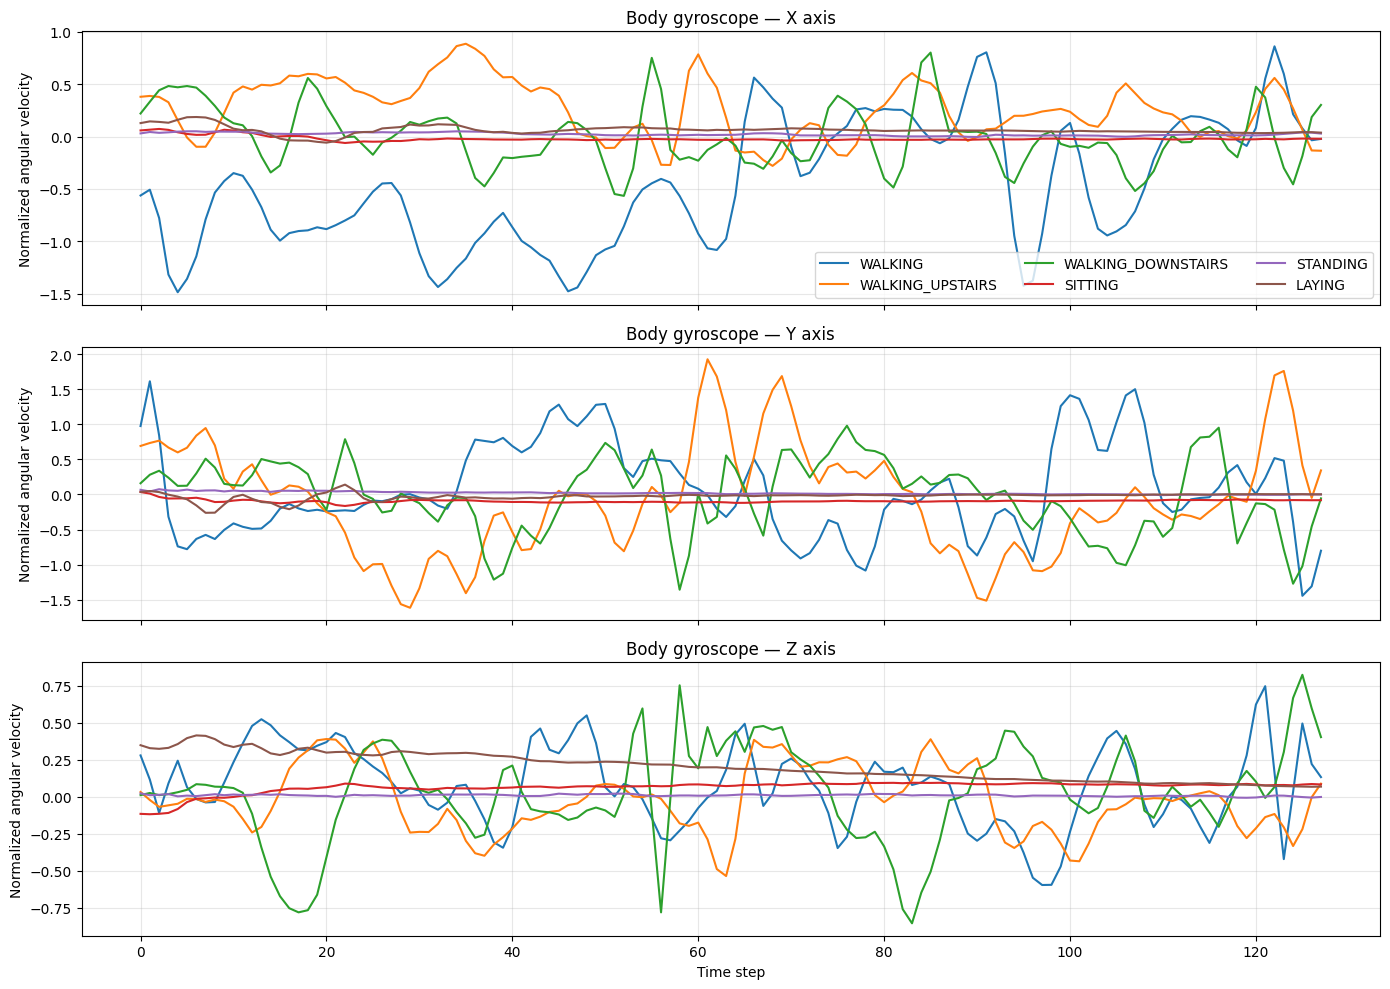

In [ ]:
# Load one example window per activity from the training set
activity_samples = {
    activity_id: np.where(y_train == activity_id)[0][0]
    for activity_id in range(1, 7)
}

def load_inertial_signal(sensor_name, split="train"):
    path = (
        DATASET_DIR / split / "Inertial Signals" /
        f"{sensor_name}_{split}.txt"
    )
    return pd.read_csv(path, sep=r"\s+", header=None)

body_acc = {
    axis: load_inertial_signal(f"body_acc_{axis}")
    for axis in ["x", "y", "z"]
}
body_gyro = {
    axis: load_inertial_signal(f"body_gyro_{axis}")
    for axis in ["x", "y", "z"]
}

fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
for ax, axis in zip(axes, ["x", "y", "z"]):
    for activity_id, sample_idx in activity_samples.items():
        ax.plot(
            body_acc[axis].iloc[sample_idx].values,
            label=label_map[activity_id]
        )
    ax.set_title(f"Body acceleration — {axis.upper()} axis")
    ax.set_ylabel("Normalized acceleration")
    ax.grid(alpha=0.3)
axes[-1].set_xlabel("Time step")
axes[0].legend(ncol=3)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
for ax, axis in zip(axes, ["x", "y", "z"]):
    for activity_id, sample_idx in activity_samples.items():
        ax.plot(
            body_gyro[axis].iloc[sample_idx].values,
            label=label_map[activity_id]
        )
    ax.set_title(f"Body gyroscope — {axis.upper()} axis")
    ax.set_ylabel("Normalized angular velocity")
    ax.grid(alpha=0.3)
axes[-1].set_xlabel("Time step")
axes[0].legend(ncol=3)
plt.tight_layout()
plt.show()

### Body-acceleration magnitude

The magnitude combines the three body-acceleration axes:

\[
a_{mag} = \sqrt{a_x^2 + a_y^2 + a_z^2}
\]

It gives a single measure of the overall body-acceleration magnitude, independent of the sign of an individual axis.

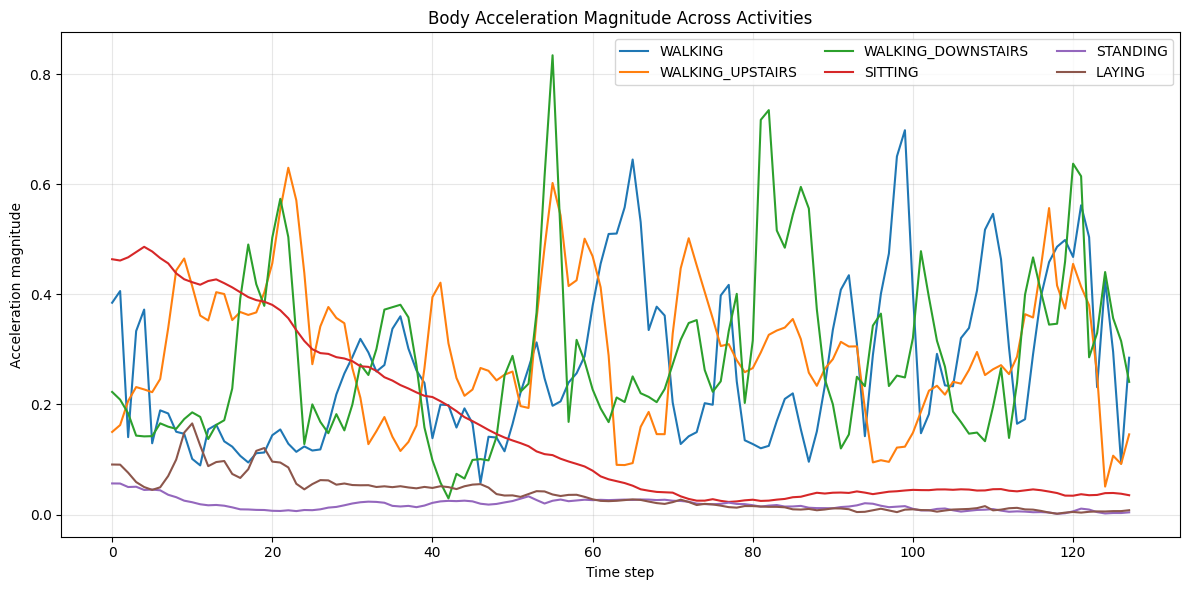

In [ ]:
body_acc_magnitude = np.sqrt(
    body_acc["x"]**2 + body_acc["y"]**2 + body_acc["z"]**2
)

plt.figure(figsize=(12, 6))
for activity_id, sample_idx in activity_samples.items():
    plt.plot(
        body_acc_magnitude.iloc[sample_idx].values,
        label=label_map[activity_id]
    )

plt.title("Body Acceleration Magnitude Across Activities")
plt.xlabel("Time step")
plt.ylabel("Acceleration magnitude")
plt.legend(ncol=3)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Build 28 custom statistical features

For each window, calculate seven statistics from each of four signals:
- Body acceleration X
- Body acceleration Y
- Body acceleration Z
- Body-acceleration magnitude

The seven statistics are mean, standard deviation, minimum, maximum, median, range, and root mean square (RMS). This produces 7 × 4 = **28 features per window**.

The same feature extraction function is applied to the training and test data.

In [ ]:
def extract_features(signal):
    result = pd.DataFrame(index=signal.index)
    result["mean"] = signal.mean(axis=1)
    result["std"] = signal.std(axis=1)
    result["min"] = signal.min(axis=1)
    result["max"] = signal.max(axis=1)
    result["median"] = signal.median(axis=1)
    result["range"] = signal.max(axis=1) - signal.min(axis=1)
    result["rms"] = np.sqrt((signal ** 2).mean(axis=1))
    return result

def build_custom_feature_matrix(split):
    acc = {
        axis: load_inertial_signal(f"body_acc_{axis}", split)
        for axis in ["x", "y", "z"]
    }
    magnitude = np.sqrt(acc["x"]**2 + acc["y"]**2 + acc["z"]**2)

    parts = []
    for prefix, signal in [
        ("x", acc["x"]),
        ("y", acc["y"]),
        ("z", acc["z"]),
        ("mag", magnitude)
    ]:
        part = extract_features(signal)
        part.columns = [f"{prefix}_{name}" for name in part.columns]
        parts.append(part)

    return pd.concat(parts, axis=1)

X_28 = build_custom_feature_matrix("train")
X_test_28 = build_custom_feature_matrix("test")

print("Custom training features:", X_28.shape)
print("Custom test features:", X_test_28.shape)

Custom training features: (7352, 28)
Custom test features: (2947, 28)


## 5. Random Forest with 28 custom features

Train a Random Forest using the custom statistical features and evaluate it on the official test set.

In [ ]:
rf_28 = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

rf_28.fit(X_28, y_train)
pred_28 = rf_28.predict(X_test_28)

accuracy_28 = accuracy_score(y_test, pred_28)
print(f"28-feature Random Forest accuracy: {accuracy_28 * 100:.2f}%")

print(classification_report(
    y_test,
    pred_28,
    labels=[1, 2, 3, 4, 5, 6],
    target_names=[label_map[i] for i in range(1, 7)],
    zero_division=0
))

28-feature Random Forest accuracy: 72.51%
                    precision    recall  f1-score   support

           WALKING       0.65      0.74      0.69       496
  WALKING_UPSTAIRS       0.62      0.58      0.60       471
WALKING_DOWNSTAIRS       0.93      0.85      0.89       420
           SITTING       0.67      0.52      0.58       491
          STANDING       0.66      0.79      0.72       532
            LAYING       0.86      0.87      0.86       537

          accuracy                           0.73      2947
         macro avg       0.73      0.72      0.72      2947
      weighted avg       0.73      0.73      0.72      2947



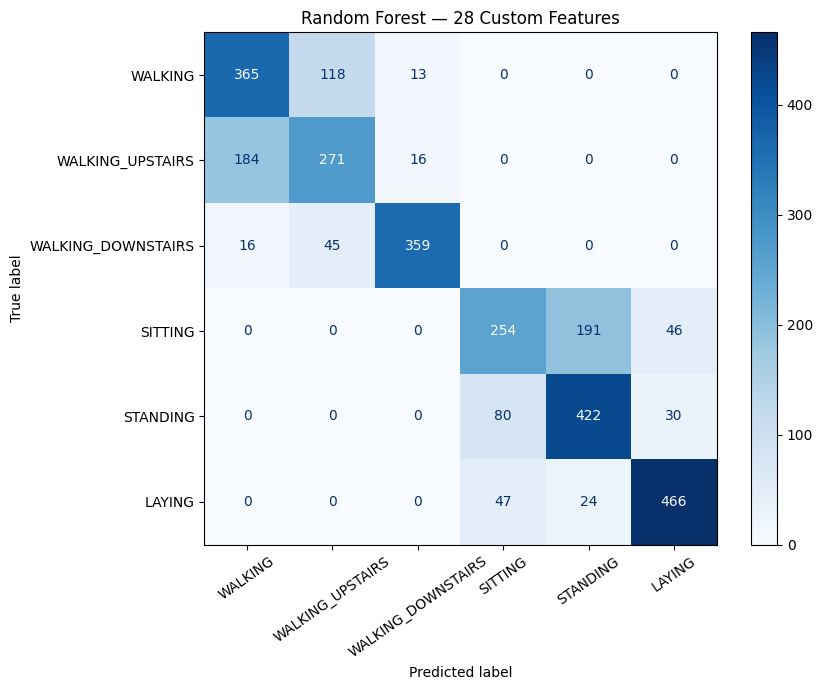

In [ ]:
cm_28 = confusion_matrix(y_test, pred_28, labels=[1, 2, 3, 4, 5, 6])
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_28,
    display_labels=[label_map[i] for i in range(1, 7)]
)
fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(ax=ax, cmap="Blues", xticks_rotation=35, values_format="d")
plt.title("Random Forest — 28 Custom Features")
plt.tight_layout()
plt.show()

### Interpretation of the 28-feature model

The recorded test accuracy was **72.51%**.

The class report showed that Sitting was particularly difficult for this feature set (F1-score about 0.58), while Walking Downstairs performed better (F1-score about 0.89). These seven summary statistics compress each 128-step signal window into a small number of values, so some temporal and frequency information is not represented.

## 6. Random Forest with the 561 dataset-provided features

The UCI HAR dataset also provides 561 engineered features for each window. These include time-domain and frequency-domain measurements derived from the inertial signals.

These are **not raw sensor readings**. They are a richer, precomputed feature representation supplied with the dataset.

In [ ]:
rf_561 = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

rf_561.fit(X_561, y_train)
pred_561 = rf_561.predict(X_test_561)

accuracy_561 = accuracy_score(y_test, pred_561)
print(f"561-feature Random Forest accuracy: {accuracy_561 * 100:.2f}%")

print(classification_report(
    y_test,
    pred_561,
    labels=[1, 2, 3, 4, 5, 6],
    target_names=[label_map[i] for i in range(1, 7)],
    zero_division=0
))

561-feature Random Forest accuracy: 92.60%
                    precision    recall  f1-score   support

           WALKING       0.89      0.97      0.93       496
  WALKING_UPSTAIRS       0.90      0.91      0.90       471
WALKING_DOWNSTAIRS       0.96      0.85      0.90       420
           SITTING       0.91      0.89      0.90       491
          STANDING       0.90      0.92      0.91       532
            LAYING       1.00      1.00      1.00       537

          accuracy                           0.93      2947
         macro avg       0.93      0.92      0.92      2947
      weighted avg       0.93      0.93      0.93      2947



,Model,Accuracy (%)
0,Random Forest — 28 custom features,72.514421
1,Random Forest — 561 UCI features,92.602647


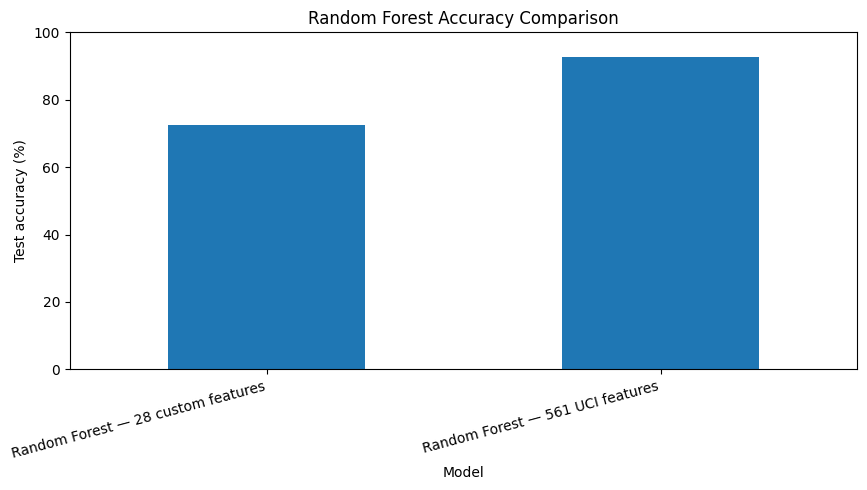

In [ ]:
model_comparison = pd.DataFrame({
    "Model": ["Random Forest — 28 custom features",
              "Random Forest — 561 UCI features"],
    "Accuracy (%)": [accuracy_28 * 100, accuracy_561 * 100]
})
display(model_comparison)

model_comparison.plot(
    x="Model", y="Accuracy (%)", kind="bar",
    legend=False, figsize=(9, 5), ylim=(0, 100)
)
plt.title("Random Forest Accuracy Comparison")
plt.ylabel("Test accuracy (%)")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

### Interpretation of the model comparison

| Model | Test accuracy |
|---|---:|
| Random Forest — 28 custom features | **72.51%** |
| Random Forest — 561 UCI features | **92.60%** |

The 561-feature model performed about **20.09 percentage points** better on the official test set. This suggests that the richer engineered representation contains useful information that was lost when the raw windows were reduced to only 28 summary statistics.

The comparison is between two feature representations using the same Random Forest settings and the same official train/test split.

## 7. Feature importance for the 561-feature model

Pair the model's feature-importance scores with the names in `features.txt`. The importance values are impurity-based Random Forest importances: they describe how useful features were for splitting in this fitted model. They are not causal explanations.

,feature,importance
40,tGravityAcc-mean()-X,0.037691
52,tGravityAcc-min()-X,0.031289
41,tGravityAcc-mean()-Y,0.030210
558,"angle(X,gravityMean)",0.027002
56,tGravityAcc-energy()-X,0.025297
53,tGravityAcc-min()-Y,0.023806
559,"angle(Y,gravityMean)",0.022755
50,tGravityAcc-max()-Y,0.022663
49,tGravityAcc-max()-X,0.020773
57,tGravityAcc-energy()-Y,0.015997


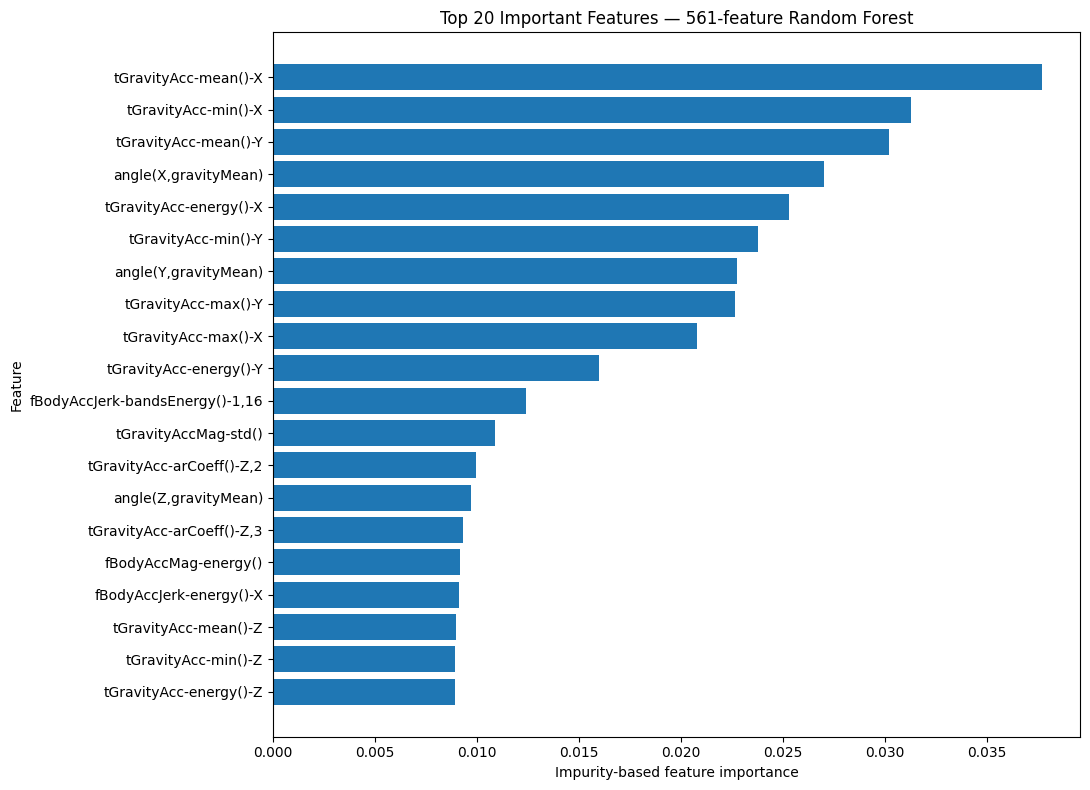

In [ ]:
feature_info = pd.read_csv(
    DATASET_DIR / "features.txt",
    sep=r"\s+",
    header=None,
    names=["feature_id", "feature"]
)

feature_names = feature_info["feature"].to_numpy()

importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": rf_561.feature_importances_
}).sort_values("importance", ascending=False)

display(importance_df.head(20))

top_20 = importance_df.head(20).sort_values("importance")
plt.figure(figsize=(11, 8))
plt.barh(top_20["feature"], top_20["importance"])
plt.title("Top 20 Important Features — 561-feature Random Forest")
plt.xlabel("Impurity-based feature importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

### Interpretation of feature importance

The top-ranked features were dominated by gravity-related acceleration measurements and orientation angles. Examples included `tGravityAcc-mean()-X`, `tGravityAcc-min()-X`, `tGravityAcc-mean()-Y`, and `angle(X,gravityMean)`.

This is plausible because gravity-related measurements provide information about the phone's orientation, which can help distinguish static postures such as sitting, standing, and laying. Other body-acceleration and frequency-domain features also appeared among the top 20.

**Caution:** correlated features can share or redistribute importance. A high importance score does not prove that a feature is essential on its own.

## 8. Ablation experiment: remove gravity and orientation features

An ablation experiment removes a selected group of inputs and retrains the model to test how performance changes.

Here, remove features whose names contain `GravityAcc` or `angle(`. The original model uses 561 features; the reduced model retains 501.

In [ ]:
remove_mask = np.array([
    ("GravityAcc" in name) or ("angle(" in name)
    for name in feature_names
])

X_no_gravity = X_561.loc[:, ~remove_mask]
X_test_no_gravity = X_test_561.loc[:, ~remove_mask]

print("Original feature count:", X_561.shape[1])
print("Remaining feature count:", X_no_gravity.shape[1])

rf_no_gravity = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)
rf_no_gravity.fit(X_no_gravity, y_train)
pred_no_gravity = rf_no_gravity.predict(X_test_no_gravity)

accuracy_no_gravity = accuracy_score(y_test, pred_no_gravity)
print(f"Accuracy without gravity/orientation features: {accuracy_no_gravity * 100:.2f}%")

Original feature count: 561
Remaining feature count: 501
Accuracy without gravity/orientation features: 90.23%


In [ ]:
report_full = classification_report(
    y_test, pred_561, labels=[1, 2, 3, 4, 5, 6],
    output_dict=True, zero_division=0
)
report_reduced = classification_report(
    y_test, pred_no_gravity, labels=[1, 2, 3, 4, 5, 6],
    output_dict=True, zero_division=0
)

ablation_comparison = pd.DataFrame({
    "Activity": [label_map[i] for i in range(1, 7)],
    "With gravity/orientation": [report_full[str(i)]["f1-score"] for i in range(1, 7)],
    "Without gravity/orientation": [report_reduced[str(i)]["f1-score"] for i in range(1, 7)]
})
ablation_comparison["F1 change"] = (
    ablation_comparison["Without gravity/orientation"]
    - ablation_comparison["With gravity/orientation"]
)
display(ablation_comparison)

,Activity,With gravity/orientation,Without gravity/orientation,F1 change
0,WALKING,0.928295,0.955401,0.027107
1,WALKING_UPSTAIRS,0.904110,0.931677,0.027567
2,WALKING_DOWNSTAIRS,0.902900,0.898623,-0.004277
3,SITTING,0.900103,0.833154,-0.066949
4,STANDING,0.909767,0.888499,-0.021269
5,LAYING,1.000000,0.903042,-0.096958


### Ablation results and interpretation

| Metric | With all 561 features | Without gravity/orientation |
|---|---:|---:|
| Test accuracy | **92.60%** | **90.23%** |
| Number of features | 561 | 501 |

Removing 60 gravity/orientation features reduced accuracy by approximately **2.38 percentage points**.

Per-activity F1-score changes from the experiment:

- Walking: improved from 0.9283 to 0.9554.
- Walking Upstairs: improved from 0.9041 to 0.9317.
- Walking Downstairs: nearly unchanged (0.9029 to 0.8986).
- Sitting: decreased from 0.9001 to 0.8332.
- Standing: decreased from 0.9098 to 0.8885.
- Laying: decreased from 1.0000 to 0.9030.

This suggests that gravity/orientation features were particularly helpful for recognizing static postures, especially laying and sitting, in this experiment. Dynamic activities remained recognizable using other signal information.

Walking and Walking Upstairs improved after feature removal. This can happen because the remaining features provide a different set of splits and some removed features may have been redundant or less helpful for those classes.

The ablation result is evidence about this fitted model and dataset split; it does not prove that gravity is universally unnecessary for dynamic activities.

## 9. Prepare raw sensor signals for a 1D CNN

The previous Random Forest experiments used engineered features. A 1D CNN can instead learn patterns directly from time-series sensor readings.

The raw input will contain nine channels:
- Body acceleration: X, Y, Z
- Body gyroscope: X, Y, Z
- Total acceleration: X, Y, Z

Each sample has 128 time steps, so the expected input shape is `(samples, 128, 9)`.

In [ ]:
sensor_names = [
    "body_acc_x", "body_acc_y", "body_acc_z",
    "body_gyro_x", "body_gyro_y", "body_gyro_z",
    "total_acc_x", "total_acc_y", "total_acc_z"
]

def load_raw_signals(split):
    channels = []
    for sensor in sensor_names:
        path = (
            DATASET_DIR / split / "Inertial Signals" /
            f"{sensor}_{split}.txt"
        )
        channels.append(np.loadtxt(path))
    return np.stack(channels, axis=-1)

X_raw_train = load_raw_signals("train")
X_raw_test = load_raw_signals("test")

print("Raw training shape:", X_raw_train.shape)
print("Raw test shape:", X_raw_test.shape)

Raw training shape: (7352, 128, 9)
Raw test shape: (2947, 128, 9)


### Subject-independent training/validation split

Do not randomly split individual windows for validation: windows from the same participant could appear in both subsets. Instead, reserve complete participants from the official training set for validation.

The official test set remains untouched for final evaluation.

In [ ]:
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(X_raw_train, y_train, groups=subjects_train)
)

X_cnn_train = X_raw_train[train_idx]
X_cnn_val = X_raw_train[val_idx]

y_cnn_train = y_train[train_idx] - 1
y_cnn_val = y_train[val_idx] - 1
y_cnn_test = y_test - 1

train_subject_set = set(subjects_train[train_idx])
val_subject_set = set(subjects_train[val_idx])

print("CNN training shape:", X_cnn_train.shape)
print("CNN validation shape:", X_cnn_val.shape)
print("Training subjects:", sorted(train_subject_set))
print("Validation subjects:", sorted(val_subject_set))
print("Subject overlap:", train_subject_set & val_subject_set)
print("CNN training labels:", np.unique(y_cnn_train))
print("CNN validation labels:", np.unique(y_cnn_val))
print("CNN test labels:", np.unique(y_cnn_test))

CNN training shape: (5551, 128, 9)
CNN validation shape: (1801, 128, 9)
Training subjects: [np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(11), np.int64(14), np.int64(16), np.int64(17), np.int64(19), np.int64(21), np.int64(22), np.int64(23), np.int64(26), np.int64(28), np.int64(29), np.int64(30)]
Validation subjects: [np.int64(1), np.int64(3), np.int64(15), np.int64(25), np.int64(27)]
Subject overlap: set()
CNN training labels: [0 1 2 3 4 5]
CNN validation labels: [0 1 2 3 4 5]
CNN test labels: [0 1 2 3 4 5]


the model

## 10. Conclusions

### Main findings

1. **The UCI HAR dataset provides a useful benchmark** for recognizing six activities from smartphone inertial sensor measurements. Its official training and test participants do not overlap.
2. **The 28-feature Random Forest achieved 72.51% test accuracy.** A compact set of simple statistics was useful, but it did not capture all the information present in the sensor windows.
3. **The 561-feature Random Forest achieved 92.60% test accuracy.** This was approximately 20.09 percentage points higher than the custom 28-feature model, showing the value of the richer dataset-provided engineered features.
4. **Gravity and orientation features ranked highly** in the 561-feature Random Forest. Their importance is consistent with the need to distinguish body and phone orientation across different postures.
5. **The gravity/orientation ablation reduced overall accuracy to 90.23%.** The largest F1-score reductions occurred for Laying and Sitting, while Walking and Walking Upstairs improved slightly. This shows that feature usefulness differs by activity and that feature importance alone does not determine the effect of removing a feature group.
6. **Raw sensor windows have been prepared for deep learning.** The nine-channel input has shape `(samples, 128, 9)`, and a subject-independent training/validation split has been created without participant overlap.

### Current project status

The completed experiments in this notebook are the custom-feature Random Forest, 561-feature Random Forest, feature-importance analysis, and gravity/orientation ablation study.

**Next step:** Build, train, tune, and evaluate a 1D CNN using the prepared raw sensor windows. The CNN results are not included yet, so no conclusion about CNN performance can be made at this stage.

### Overall conclusion

The experiments demonstrate that human activity recognition benefits from informative representations of smartphone sensor data. A small set of manually selected statistical features provides a baseline, while the 561-feature representation delivers substantially stronger performance. The feature ablation experiment further shows that gravity and orientation information contributes especially to recognizing static postures. The next stage is to investigate whether a 1D CNN can learn useful temporal patterns directly from raw sensor signals and how its subject-independent test performance compares with the Random Forest baseline.

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

cnn_model = models.Sequential([
    layers.Input(shape=(128, 9)),

    layers.Conv1D(64, kernel_size=5, activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling1D(pool_size=2),

    layers.Conv1D(128, kernel_size=5, activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling1D(pool_size=2),

    layers.GlobalAveragePooling1D(),

    layers.Dropout(0.3),

    layers.Dense(64, activation="relu"),
    layers.Dense(6, activation="softmax")
])

cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 124, 64)        │         2,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 124, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 62, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 58, 128)        │        41,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 58, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 29, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 53,446 (208.77 KB)

 Trainable params: 53,062 (207.27 KB)

 Non-trainable params: 384 (1.50 KB)

In [ ]:
cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=0.00001
)

In [ ]:
history = cnn_model.fit(
    X_cnn_train,
    y_cnn_train,

    validation_data=(
        X_cnn_val,
        y_cnn_val
    ),

    epochs=50,
    batch_size=64,

    callbacks=[
        early_stop,
        reduce_lr
    ],

    verbose=1
)

Epoch 1/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 7s 54ms/step - accuracy: 0.8559 - loss: 0.3903 - val_accuracy: 0.5019 - val_loss: 1.3794 - learning_rate: 0.0010
Epoch 2/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 4s 43ms/step - accuracy: 0.9360 - loss: 0.1553 - val_accuracy: 0.5203 - val_loss: 1.3724 - learning_rate: 0.0010
Epoch 3/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 4s 48ms/step - accuracy: 0.9402 - loss: 0.1389 - val_accuracy: 0.6663 - val_loss: 1.0439 - learning_rate: 0.0010
Epoch 4/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 5s 53ms/step - accuracy: 0.9400 - loss: 0.1323 - val_accuracy: 0.7485 - val_loss: 0.6479 - learning_rate: 0.0010
Epoch 5/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 4s 43ms/step - accuracy: 0.9377 - loss: 0.1343 - val_accuracy: 0.9439 - val_loss: 0.2165 - learning_rate: 0.0010
Epoch 6/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 4s 43ms/step - accuracy: 0.9445 - loss: 0.1277 - val_accuracy: 0.9550 - val_loss: 0.1548 - learning_rate: 0.0010
Epoch 7/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 5s 59ms/step - accuracy: 0.9442 - loss: 0.1212 - val_acc

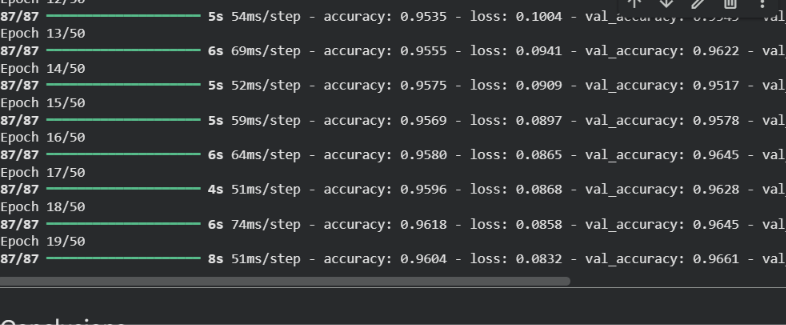

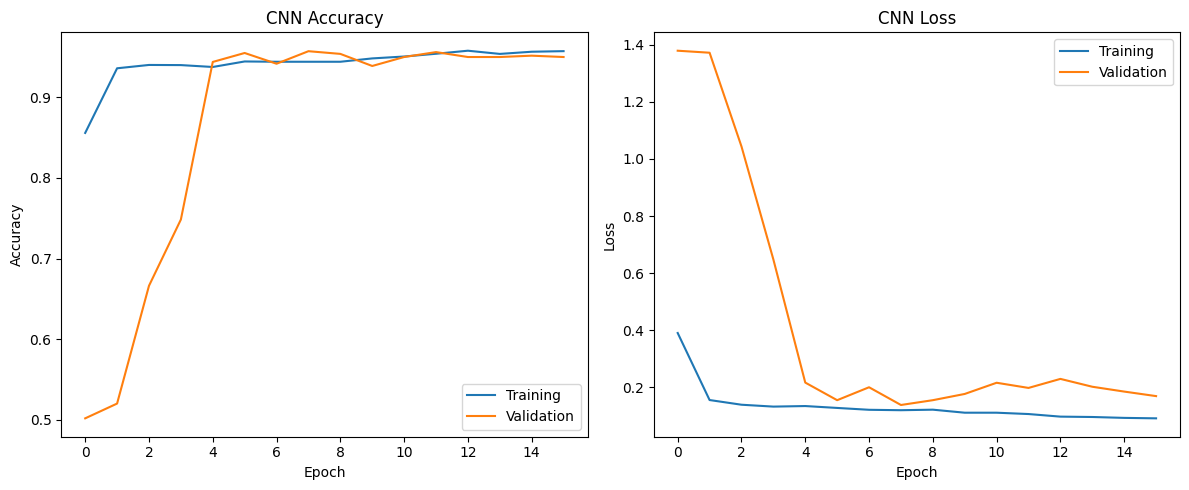

In [ ]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

test on unseen data

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Evaluate on the official test set
test_loss, test_accuracy = cnn_model.evaluate(
    X_raw_test,
    y_cnn_test,
    verbose=0
)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

# Generate predictions
y_pred_probs = cnn_model.predict(X_raw_test)
y_pred = y_pred_probs.argmax(axis=1)

# Activity names
class_names = [
    "WALKING",
    "WALKING_UPSTAIRS",
    "WALKING_DOWNSTAIRS",
    "SITTING",
    "STANDING",
    "LAYING"
]

print(classification_report(
    y_cnn_test,
    y_pred,
    target_names=class_names
))

Test Accuracy: 92.43%
Test Loss: 0.1884
93/93 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step
                    precision    recall  f1-score   support

           WALKING       1.00      0.95      0.97       496
  WALKING_UPSTAIRS       0.95      0.98      0.97       471
WALKING_DOWNSTAIRS       0.98      0.99      0.99       420
           SITTING       0.79      0.85      0.82       491
          STANDING       0.86      0.79      0.82       532
            LAYING       0.99      1.00      0.99       537

          accuracy                           0.92      2947
         macro avg       0.93      0.93      0.93      2947
      weighted avg       0.93      0.92      0.92      2947



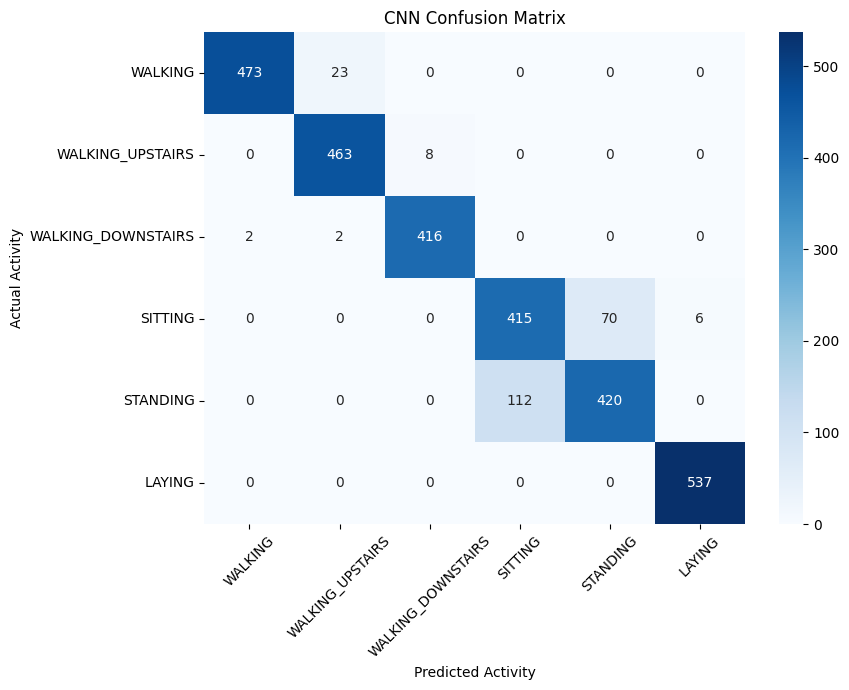

In [ ]:
cm = confusion_matrix(y_cnn_test, y_pred)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Activity")
plt.ylabel("Actual Activity")
plt.title("CNN Confusion Matrix")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")
print("\nConfusion Matrix:")
print(cm)

Test Accuracy: 92.43 %

Confusion Matrix:
[[473  23   0   0   0   0]
 [  0 463   8   0   0   0]
 [  2   2 416   0   0   0]
 [  0   0   0 415  70   6]
 [  0   0   0 112 420   0]
 [  0   0   0   0   0 537]]


In [ ]:
print(classification_report(
    y_cnn_test,
    y_pred,
    target_names=class_names,
    digits=4
))

                    precision    recall  f1-score   support

           WALKING     0.9958    0.9536    0.9743       496
  WALKING_UPSTAIRS     0.9488    0.9830    0.9656       471
WALKING_DOWNSTAIRS     0.9811    0.9905    0.9858       420
           SITTING     0.7875    0.8452    0.8153       491
          STANDING     0.8571    0.7895    0.8219       532
            LAYING     0.9890    1.0000    0.9944       537

          accuracy                         0.9243      2947
         macro avg     0.9265    0.9270    0.9262      2947
      weighted avg     0.9252    0.9243    0.9242      2947



Sitting — recall 77.39%

Out of 491 actual sitting samples, the model correctly identified 380.

That means 111 sitting samples were classified incorrectly, mostly as standing.

Standing — precision 81.49%

Out of all samples predicted as standing, only 81.49% were actually standing.

The model sometimes mistakes sitting for standing.

In [ ]:
# Calculate statistics from training data only
channel_mean = X_cnn_train.mean(axis=(0, 1), keepdims=True)
channel_std = X_cnn_train.std(axis=(0, 1), keepdims=True)

# Normalize all splits using training statistics
X_train_norm = (X_cnn_train - channel_mean) / (channel_std + 1e-8)
X_val_norm = (X_cnn_val - channel_mean) / (channel_std + 1e-8)
X_test_norm = (X_raw_test - channel_mean) / (channel_std + 1e-8)

print("Training:", X_train_norm.shape)
print("Validation:", X_val_norm.shape)
print("Testing:", X_test_norm.shape)

Training: (5551, 128, 9)
Validation: (1801, 128, 9)
Testing: (2947, 128, 9)


In [ ]:
cnn_norm = models.Sequential([
    layers.Input(shape=(128, 9)),

    layers.Conv1D(64, kernel_size=5, activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling1D(pool_size=2),

    layers.Conv1D(128, kernel_size=5, activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling1D(pool_size=2),

    layers.GlobalAveragePooling1D(),
    layers.Dropout(0.3),

    layers.Dense(64, activation="relu"),
    layers.Dense(6, activation="softmax")
])

In [ ]:
cnn_norm.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_norm = cnn_norm.fit(
    X_train_norm,
    y_cnn_train,
    validation_data=(X_val_norm, y_cnn_val),
    epochs=50,
    batch_size=64,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

Epoch 1/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 6s 54ms/step - accuracy: 0.8678 - loss: 0.3617 - val_accuracy: 0.9783 - val_loss: 0.6086 - learning_rate: 0.0010
Epoch 2/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 4s 49ms/step - accuracy: 0.9373 - loss: 0.1584 - val_accuracy: 0.9750 - val_loss: 0.2441 - learning_rate: 0.0010
Epoch 3/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 4s 42ms/step - accuracy: 0.9360 - loss: 0.1442 - val_accuracy: 0.9739 - val_loss: 0.1297 - learning_rate: 0.0010
Epoch 4/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 7s 59ms/step - accuracy: 0.9411 - loss: 0.1362 - val_accuracy: 0.9700 - val_loss: 0.1382 - learning_rate: 0.0010
Epoch 5/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 4s 42ms/step - accuracy: 0.9440 - loss: 0.1292 - val_accuracy: 0.9689 - val_loss: 0.1218 - learning_rate: 0.0010
Epoch 6/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 5s 43ms/step - accuracy: 0.9449 - loss: 0.1223 - val_accuracy: 0.9756 - val_loss: 0.1336 - learning_rate: 0.0010
Epoch 7/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 5s 58ms/step - accuracy: 0.9470 - loss: 0.1161 - val_acc

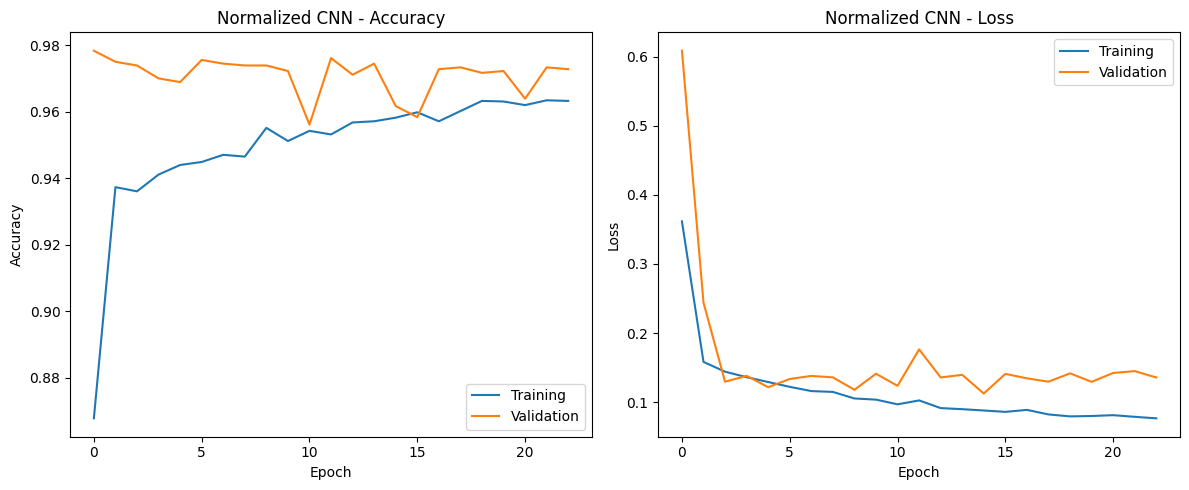

In [ ]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_norm.history["accuracy"], label="Training")
plt.plot(history_norm.history["val_accuracy"], label="Validation")
plt.title("Normalized CNN - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_norm.history["loss"], label="Training")
plt.plot(history_norm.history["val_loss"], label="Validation")
plt.title("Normalized CNN - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np

best_acc_epoch = np.argmax(history_norm.history["val_accuracy"])
best_loss_epoch = np.argmin(history_norm.history["val_loss"])

print("Best validation accuracy:")
print(f"{history_norm.history['val_accuracy'][best_acc_epoch] * 100:.2f}%")
print("Epoch:", best_acc_epoch + 1)

print("\nLowest validation loss:")
print(f"{history_norm.history['val_loss'][best_loss_epoch]:.4f}")
print("Epoch:", best_loss_epoch + 1)

Best validation accuracy:
97.83%
Epoch: 1

Lowest validation loss:
0.1126
Epoch: 15


In [ ]:
test_loss_norm, test_accuracy_norm = cnn_norm.evaluate(
    X_test_norm,
    y_cnn_test,
    verbose=0
)

print(f"Normalized CNN Test Accuracy: {test_accuracy_norm * 100:.2f}%")
print(f"Normalized CNN Test Loss: {test_loss_norm:.4f}")

print(f"\nOriginal CNN: {test_accuracy * 100:.2f}%")
print(f"Normalized CNN: {test_accuracy_norm * 100:.2f}%")
print(f"Difference: {(test_accuracy_norm - test_accuracy) * 100:+.2f} percentage points")

Normalized CNN Test Accuracy: 92.87%
Normalized CNN Test Loss: 0.2068

Original CNN: 92.43%
Normalized CNN: 92.87%
Difference: +0.44 percentage points


In [ ]:
# Original CNN: raw signals
original_loss, original_acc = cnn_model.evaluate(
    X_raw_test, y_cnn_test, verbose=0
)

# Normalized CNN: normalized signals
normalized_loss, normalized_acc = cnn_norm.evaluate(
    X_test_norm, y_cnn_test, verbose=0
)

print(f"Original CNN:   {original_acc * 100:.2f}%")
print(f"Normalized CNN: {normalized_acc * 100:.2f}%")

print(
    f"Difference: {(normalized_acc - original_acc) * 100:+.2f} "
    "percentage points"
)

Original CNN:   92.43%
Normalized CNN: 92.87%
Difference: +0.44 percentage points


In [ ]:
y_norm_probs = cnn_norm.predict(X_test_norm)
y_norm_pred = y_norm_probs.argmax(axis=1)

print(classification_report(
    y_cnn_test,
    y_norm_pred,
    target_names=class_names,
    digits=4
))

93/93 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step
                    precision    recall  f1-score   support

           WALKING     0.9822    1.0000    0.9910       496
  WALKING_UPSTAIRS     0.9617    0.9597    0.9607       471
WALKING_DOWNSTAIRS     0.9541    0.9405    0.9472       420
           SITTING     0.8587    0.7923    0.8242       491
          STANDING     0.8313    0.8797    0.8548       532
            LAYING     0.9908    1.0000    0.9954       537

          accuracy                         0.9287      2947
         macro avg     0.9298    0.9287    0.9289      2947
      weighted avg     0.9287    0.9287    0.9283      2947



In [ ]:
from sklearn.metrics import confusion_matrix

cm_norm = confusion_matrix(y_cnn_test, y_norm_pred)

print(cm_norm)

[[496   0   0   0   0   0]
 [  0 452  19   0   0   0]
 [  9  16 395   0   0   0]
 [  0   2   0 389  95   5]
 [  0   0   0  64 468   0]
 [  0   0   0   0   0 537]]


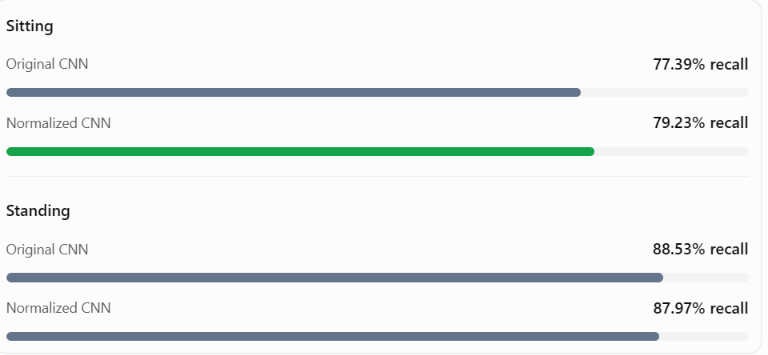